# 08 — Improving BES: why it fails on Llama-2-7B-Chat, and what would make it better in general

Part A diagnoses the Llama-2 failure and tests repairs; Part B tests general improvements on Qwen against the original setting.

In [1]:
# Environment: on Colab clone the repo, install requirements and mount Drive; then build the pairs
import os, sys, subprocess
from pathlib import Path

REPO = "https://github.com/chase-mayer/syco-erase.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/syco-erase").exists():
        subprocess.run(["git", "clone", "-q", REPO, "/content/syco-erase"], check=True)
    os.chdir("/content/syco-erase")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
elif Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, os.getcwd())
assert Path("src/experiment.py").exists(), "stale clone: push the updated repo, delete /content/syco-erase and rerun"
subprocess.run(["bash", "scripts/download_data.sh"], check=True, capture_output=True)
print(subprocess.run([sys.executable, "-m", "src.data", "--dataset", "all"],
                     check=True, capture_output=True, text=True).stdout)

Mounted at /content/drive
nlp: 9984 pairs, 32 unique questions -> pairs_nlp.jsonl  (stem match 100.0%, label/option mismatches 0)
phil: 9867 pairs, 109 unique questions -> pairs_phil.jsonl  (stem match 100.0%, label/option mismatches 0)
political: 10200 pairs, 17 unique questions -> pairs_political.jsonl  (stem match 100.0%, label/option mismatches 0)



In [2]:
# Hugging Face login for the gated Llama-2 weights (skipped in offline smoke tests)
if os.environ.get("BES_SMOKE") != "1":
    from huggingface_hub import login
    login()

In [3]:
# Load Llama-2-7B-Chat and define the layer sets used below
import glob, json, re
from dataclasses import dataclass
import numpy as np
import pandas as pd
import torch
from src import bes, experiment as E, plots, stats

cfg = E.Config(model=os.environ.get("BES_LLAMA_MODEL", "meta-llama/Llama-2-7b-chat-hf"), batch_size=8, dtype="fp16")
run = E.Runner(cfg)
nl = run.n_layers
clip = lambda ls: [l for l in ls if l < nl]
GRID_LAYERS = clip([2, 4, 6, 8, 10, 11, 12, 13, 14, 15, 16, 18, 20, 22, 24, 26, 28, 30]) if not cfg.smoke else clip([0, 1, 2, 3])
PATCH_LAYERS = clip(list(range(0, 32, 2))) if not cfg.smoke else clip([0, 1, 2, 3])
LABEL_LAYERS = clip([10, 11, 12, 13, 14, 15, 16]) if not cfg.smoke else clip([0, 1, 2])
CAA_LAYERS = clip([11, 12, 13, 14]) if not cfg.smoke else clip([0, 1, 2])
TOPK = 16
MIN_DROP = 0.03
print(cfg.model, "| layers", nl, "| grid", GRID_LAYERS)

config.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.62k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/188 [00:00<?, ?B/s]

meta-llama/Llama-2-7b-chat-hf | layers 32 | grid [2, 4, 6, 8, 10, 11, 12, 13, 14, 15, 16, 18, 20, 22, 24, 26, 28, 30]


In [4]:
# Rimsky et al.'s fitting and test items, released vectors, and the same splits as notebook 07
ref = Path("data/raw/caa_ref")
if not ref.exists():
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/nrimsky/CAA.git", str(ref)], check=True)
gen = json.load(open(ref / "datasets/generate/sycophancy/generate_dataset.json"))
test_ref = json.load(open(ref / "datasets/test/sycophancy/test_dataset_ab.json"))
mmlu_ref = json.load(open(ref / "datasets/test/mmlu/mmlu.json"))
vec = {L: torch.load(ref / f"normalized_vectors/sycophancy/vec_layer_{L}_Llama-2-7b-chat-hf.pt").float()
       for L in range(32)} if not cfg.smoke else {L: torch.randn(run.d_model) for L in range(nl)}
norm = lambda s: re.sub(r"\s+", " ", re.sub(r"\s*Answer:\s*$", "", s.strip())).strip()
pool = E.load_rows(("nlp", "political"))
by_text = {norm(r["opinion_prompt"]): r for r in pool}
fit_rows = [by_text[norm(g["question"])] for g in gen]
test_rows = [by_text[norm(t["question"])] for t in test_ref]
used = {r["uid"] for r in fit_rows + test_rows}
rest = [r for r in pool if r["uid"] not in used]
n_val, n_ext = (300, 400) if not cfg.smoke else (24, 24)
val_rows = E.sample_balanced(rest, n_val, seed=0)
rest = [r for r in rest if r["uid"] not in {v["uid"] for v in val_rows}]
ext_rows = E.sample_balanced(rest, n_ext, seed=1)
phil_rows = E.sample_balanced(E.load_rows(("phil",)), n_ext, seed=2)
if cfg.smoke:
    fit_rows = fit_rows[:30]
print(f"fit {len(fit_rows)} | validation {len(val_rows)} | their test {len(test_rows)} | extra {len(ext_rows)} | PhilPapers {len(phil_rows)}")

fit 1000 | validation 300 | their test 50 | extra 400 | PhilPapers 400


In [5]:
# Prompts, spans and scoring exactly as in notebook 07
def chat(text):
    body = re.sub(r"\s*Answer:\s*$", "", text.strip())
    return f"[INST] {body} [/INST] ("


def inst_end_spans(prompts):
    out = []
    for p in prompts:
        head = p[: p.rindex("[/INST]") + len("[/INST]")]
        out.append((len(run.tok.encode(p)) - len(run.tok.encode(head)) + 1, 0))
    return out


def make_items(rows):
    op, ne = [chat(r["opinion_prompt"]) for r in rows], [chat(r["neutral_prompt"]) for r in rows]
    it = E.Items(rows, op, ne, [r["options"] for r in rows], np.array([bes.LETTERS.index(r["matching"]) for r in rows]),
                 np.array([r["qid"] for r in rows]), np.array([r["dataset"] for r in rows]), E.make_spans(run.tok, op, ne))
    it.spans["inst_end"] = inst_end_spans(op)
    return run.baselines(it)


def score(items, iv=None, span="all"):
    raw = bes.option_probs(run.model, run.tok, items.opinion, items.options, run.device, iv=iv,
                           spans=items.spans[span], batch_size=cfg.batch_size, normalize=False)
    p = raw / raw.sum(1, keepdims=True)
    return {"raw_syco": raw[np.arange(len(p)), items.match], **bes.per_item(items.p_neutral, items.p_opinion, p, items.match)}


def summ(r):
    return {"syco": float(r["syco"].mean()), "kl": float(r["kl"].mean())}


fit, val, test, ext, phil = (make_items(r) for r in (fit_rows, val_rows, test_rows, ext_rows, phil_rows))
W = run.window_for(fit, cfg.window)
BASE = summ(score(val))
ORACLE = float(val.p_neutral[np.arange(len(val.rows)), val.match].mean())
print(f"validation: no intervention syco {BASE['syco']:.3f}, KL {BASE['kl']:.3f} | oracle (no-opinion) syco {ORACLE:.3f} | window {W}")

validation: no intervention syco 0.749, KL 1.012 | oracle (no-opinion) syco 0.503 | window 16


## 1. Diagnostics

A probe for the user's option by layer, and activation patching of the no-opinion activations over the question tokens or the last token.

In [6]:
# Fit the top-16 centred SVD directions at every grid layer (SVD on the GPU, layers in chunks to bound memory)
basis, evr = {}, {}
for i in range(0, len(GRID_LAYERS), 6):
    chunk = GRID_LAYERS[i:i + 6]
    h_op, h_ne = run.activations(fit.opinion, chunk, W), run.activations(fit.neutral, chunk, W)
    for L in chunk:
        d = (h_op.pop(L) - h_ne.pop(L)).to(run.device, torch.float32)
        d = d - d.mean(0, keepdim=True)
        _, S, Vh = torch.linalg.svd(d, full_matrices=False)
        k = min(TOPK, Vh.shape[0])
        basis[L], evr[L] = Vh[:k].cpu(), (S[:k] ** 2 / (S ** 2).sum()).cpu().numpy()
        del d, S, Vh
    torch.cuda.empty_cache()
print({L: round(float(evr[L][0]), 3) for L in GRID_LAYERS}, "<- variance explained by the top direction")

{2: 0.097, 4: 0.082, 6: 0.089, 8: 0.078, 10: 0.076, 11: 0.071, 12: 0.068, 13: 0.07, 14: 0.074, 15: 0.069, 16: 0.081, 18: 0.076, 20: 0.075, 22: 0.079, 24: 0.083, 26: 0.084, 28: 0.077, 30: 0.066} <- variance explained by the top direction


In [7]:
# Probe: can a linear classifier read the user's preferred option at the answer position? AUC: does the top direction separate (A) from (B)?
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

two_f, two_v = np.array([len(o) == 2 for o in fit.options]), np.array([len(o) == 2 for o in val.options])
y_f, y_v = (fit.match[two_f] == 0), (val.match[two_v] == 0)
last_f = run.activations([p for p, t in zip(fit.opinion, two_f) if t], GRID_LAYERS, 1)
last_v = run.activations([p for p, t in zip(val.opinion, two_v) if t], GRID_LAYERS, 1)
rows_d = []
for i in range(0, len(GRID_LAYERS), 6):
    chunk = GRID_LAYERS[i:i + 6]
    vo, vn = run.activations(val.opinion, chunk, W), run.activations(val.neutral, chunk, W)
    fo, fn = run.activations(fit.opinion, chunk, W), run.activations(fit.neutral, chunk, W)
    for L in chunk:
        u = basis[L][0]
        proj = lambda ho, hn, n: ((ho - hn).reshape(n, W, -1).mean(1) @ u).numpy()
        s_f, s_v = proj(fo.pop(L), fn.pop(L), len(fit.rows))[two_f], proj(vo.pop(L), vn.pop(L), len(val.rows))[two_v]
        sign = 1.0 if s_f[y_f].mean() >= s_f[~y_f].mean() else -1.0
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)).fit(last_f[L].numpy(), y_f)
        rows_d.append({"layer": L, "evr_top": float(evr[L][0]), "auc_top_direction": stats.auc(sign * s_v, y_v),
                       "probe_acc_answer_pos": float(clf.score(last_v[L].numpy(), y_v))})
diag = pd.DataFrame(rows_d)
E.save(diag, "llama_imp_diagnostics")
diag.round(3)

,layer,evr_top,auc_top_direction,probe_acc_answer_pos
0,2,0.097,0.451,0.793
1,4,0.082,0.415,0.843
2,6,0.089,0.589,0.853
3,8,0.078,0.587,0.867
4,10,0.076,0.576,0.950
5,11,0.071,0.566,0.960
6,12,0.068,0.493,0.967
7,13,0.070,0.534,0.967
8,14,0.074,0.561,0.980
9,15,0.069,0.537,0.980


In [8]:
# Patching map: replace opinion-prompt activations with the no-opinion prompt's at one layer, over the question span or the last token
@dataclass
class Patch(bes.Intervention):
    source: torch.Tensor | None = None
    lengths: list | None = None

    def edit(self, h):
        out = h.clone()
        for b, q in enumerate(self.lengths):
            if q > 0:
                out[b, -q:, :] = self.source[b, -q:, :].to(h.dtype)
        return out


backbone = getattr(run.model, "model", run.model)
n_patch = 120 if not cfg.smoke else 16
pidx = np.arange(n_patch)
q_len = [q for q, _ in val.spans["question"]]


def patched_syco(L, lengths):
    out = []
    for i in range(0, n_patch, cfg.batch_size):
        sl = slice(i, min(i + cfg.batch_size, n_patch))
        store = {}
        hdl = bes.layer_module(run.model, L).register_forward_hook(
            lambda m, inp, o: store.__setitem__("h", (o[0] if isinstance(o, tuple) else o).detach()))
        with torch.no_grad():
            backbone(**bes._encode(run.tok, val.neutral[sl], run.device))
        hdl.remove()
        iv = Patch(layers=[L], source=store["h"], lengths=lengths[sl])
        out.append(bes.option_probs(run.model, run.tok, val.opinion[sl], val.options[sl], run.device, iv=iv,
                                    spans=None, batch_size=cfg.batch_size))
    p = np.concatenate(out)
    return summ(bes.per_item(val.p_neutral[pidx], val.p_opinion[pidx], p, val.match[pidx]))


base_p = summ(bes.per_item(val.p_neutral[pidx], val.p_opinion[pidx], val.p_opinion[pidx], val.match[pidx]))
rows_p = []
for L in PATCH_LAYERS:
    for name, lengths in (("question", q_len), ("last", [1] * len(val.rows))):
        rows_p.append({"layer": L, "patched": name, **patched_syco(L, lengths)})
patching = pd.DataFrame(rows_p)
E.save(patching, "llama_imp_patching")
print(f"{n_patch} items | no patching: syco {base_p['syco']:.3f}, KL {base_p['kl']:.3f} | oracle {val.p_neutral[pidx, val.match[pidx]].mean():.3f}")
patching.pivot(index="layer", columns="patched", values=["syco", "kl"]).round(3)

120 items | no patching: syco 0.763, KL 1.187 | oracle 0.478


syco              kl         
patched   last question   last question
layer                                  
0        0.761    0.770  1.166    1.121
2        0.762    0.761  1.175    0.973
4        0.764    0.725  1.186    0.773
6        0.765    0.674  1.185    0.534
8        0.758    0.632  1.151    0.278
10       0.733    0.562  0.887    0.093
12       0.723    0.518  0.784    0.042
14       0.602    0.492  0.229    0.012
16       0.501    0.484  0.034    0.004
18       0.487    0.481  0.019    0.002
20       0.484    0.482  0.011    0.002
22       0.480    0.480  0.007    0.001
24       0.477    0.479  0.003    0.000
26       0.478    0.480  0.003    0.001
28       0.477    0.479  0.002    0.001
30       0.479    0.478  0.001    0.000

PosixPath('/content/syco-erase/results/fig_llama_diagnostics.png')

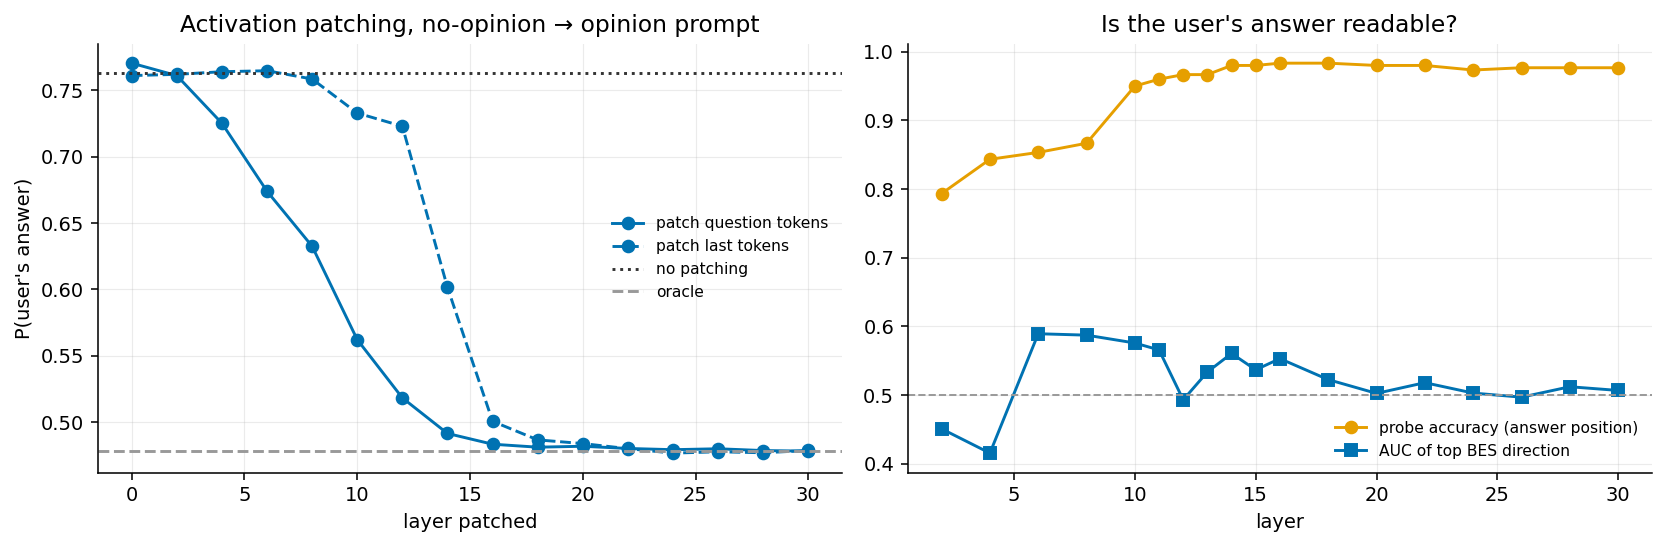

In [9]:
# Figure: patching map and probe by layer
fig, axes = plots.subplots(1, 2, figsize=(12, 4))
for name, ls in (("question", "-"), ("last", "--")):
    d = patching[patching.patched == name]
    axes[0].plot(d.layer, d.syco, ls, marker="o", color=plots.COLORS["BES"], label=f"patch {name} tokens")
axes[0].axhline(base_p["syco"], color=plots.COLORS["none"], ls=":", label="no patching")
axes[0].axhline(val.p_neutral[pidx, val.match[pidx]].mean(), color=plots.COLORS["oracle"], ls="--", label="oracle")
axes[0].set_xlabel("layer patched"); axes[0].set_ylabel("P(user's answer)"); axes[0].set_title("Activation patching, no-opinion → opinion prompt")
axes[1].plot(diag.layer, diag.probe_acc_answer_pos, "-o", color=plots.COLORS["CAA"], label="probe accuracy (answer position)")
axes[1].plot(diag.layer, diag.auc_top_direction, "-s", color=plots.COLORS["BES"], label="AUC of top BES direction")
axes[1].axhline(0.5, color=plots.COLORS["oracle"], ls="--", lw=1)
axes[1].set_xlabel("layer"); axes[1].set_title("Is the user's answer readable?")
for ax in axes:
    ax.legend(frameon=False, fontsize=8); plots.style(ax)
fig.tight_layout(); E.save_fig(fig, "fig_llama_diagnostics")

## 2–3. Full grid with a selection rule that requires a real reduction

Every layer, rank and span; a setting qualifies only if it lowers sycophancy by at least 0.03.

In [10]:
# Grid over layer × rank × span at s = 1, band 0
def pick(df, min_drop=MIN_DROP):
    ok = df[df.syco <= BASE["syco"] - min_drop]
    if len(ok):
        return ok.sort_values("kl").iloc[0], True
    return df.sort_values("syco").iloc[0], False


rows_g = []
for L in GRID_LAYERS:
    for rank in (1, 2, 4):
        for span in ("question", "all"):
            r = summ(score(val, bes.ProjectOut(layers=[L], basis=basis[L][:rank], strength=1.0), span))
            rows_g.append({"layer": L, "rank": rank, "span": span, "band": 0, "strength": 1.0, **r})
grid = pd.DataFrame(rows_g)
E.save(grid, "llama_imp_grid")
g_best, g_ok = pick(grid)
print(f"eligible settings (syco <= {BASE['syco'] - MIN_DROP:.3f}): {int((grid.syco <= BASE['syco'] - MIN_DROP).sum())} of {len(grid)}")
print("grid pick" + ("" if g_ok else " (nothing eligible; largest reduction shown)") + ":", g_best.to_dict())
grid.pivot_table(index="layer", columns=["span", "rank"], values="syco").round(3)

eligible settings (syco <= 0.719): 7 of 108
grid pick: {'layer': 8, 'rank': 4, 'span': 'all', 'band': 0, 'strength': 1.0, 'syco': 0.6795343160629272, 'kl': 0.5848289132118225}


span     all               question              
rank       1      2      4        1      2      4
layer                                            
2      0.743  0.759  0.752    0.746  0.748  0.754
4      0.736  0.738  0.720    0.746  0.744  0.739
6      0.755  0.774  0.777    0.748  0.751  0.761
8      0.747  0.751  0.680    0.748  0.749  0.751
10     0.756  0.753  0.745    0.756  0.750  0.752
11     0.756  0.756  0.751    0.756  0.747  0.736
12     0.754  0.733  0.707    0.754  0.732  0.709
13     0.746  0.718  0.704    0.746  0.717  0.708
14     0.750  0.748  0.739    0.751  0.749  0.744
15     0.748  0.742  0.740    0.750  0.744  0.746
16     0.750  0.751  0.742    0.751  0.753  0.743
18     0.746  0.744  0.755    0.747  0.747  0.751
20     0.750  0.751  0.759    0.749  0.750  0.753
22     0.748  0.749  0.749    0.747  0.750  0.750
24     0.751  0.752  0.752    0.749  0.752  0.752
26     0.750  0.752  0.750    0.750  0.752  0.751
28     0.745  0.749  0.746    0.747  0.750  0.747
30     0.746  0.750  0.751    0.748  0.750  0.751

In [11]:
# Refine band and strength at the grid pick
rows_r = []
for band in (0, 1, 2):
    for s in (0.5, 0.75, 1.0):
        iv = bes.ProjectOut(layers=E.band_layers(int(g_best.layer), band, nl), basis=basis[int(g_best.layer)][:int(g_best["rank"])], strength=s)
        rows_r.append({"layer": int(g_best.layer), "rank": int(g_best["rank"]), "span": g_best.span, "band": band, "strength": s, **summ(score(val, iv, g_best.span))})
refine = pd.DataFrame(rows_r)
E.save(refine, "llama_imp_refine")
svd_best, svd_ok = pick(refine)
print("SVD family pick" + ("" if svd_ok else " (nothing eligible)") + ":", svd_best.to_dict())
refine.round(3)

SVD family pick: {'layer': 8, 'rank': 4, 'span': 'all', 'band': 2, 'strength': 1.0, 'syco': 0.6829215288162231, 'kl': 0.4709043502807617}


,layer,rank,span,band,strength,syco,kl
0,8,4,all,0,0.50,0.736,0.990
1,8,4,all,0,0.75,0.712,0.837
2,8,4,all,0,1.00,0.680,0.585
3,8,4,all,1,0.50,0.705,0.775
4,8,4,all,1,0.75,0.688,0.593
5,8,4,all,1,1.00,0.685,0.536
6,8,4,all,2,0.50,0.694,0.619
7,8,4,all,2,0.75,0.684,0.499
8,8,4,all,2,1.00,0.683,0.471


## 4. Directions chosen by their effect

Each of the top 16 directions removed alone; the helpful ones removed together.

In [12]:
# Single-direction removals and the "causal subset" at a few layers
cand_layers = sorted({int(g_best.layer), *[l for l in (12, 13) if l in basis],
                      *grid.groupby("layer").syco.min().nsmallest(2).index.tolist()})
rows_s, subset_rows = [], []
for L in cand_layers:
    single = []
    for i in range(basis[L].shape[0]):
        r = summ(score(val, bes.ProjectOut(layers=[L], basis=basis[L][i:i + 1], strength=1.0), "all"))
        single.append({"layer": L, "direction": i, "evr": float(evr[L][i]), **r})
    rows_s += single
    helpful = [d["direction"] for d in single if d["syco"] <= BASE["syco"] - 0.01]
    if helpful:
        r = summ(score(val, bes.ProjectOut(layers=[L], basis=basis[L][helpful], strength=1.0), "all"))
        subset_rows.append({"layer": L, "directions": helpful, "n": len(helpful), **r})
        print(f"layer {L}: {len(helpful)} helpful direction(s) {helpful} -> together syco {r['syco']:.3f}, KL {r['kl']:.3f}")
    else:
        print(f"layer {L}: no single direction lowers sycophancy by 0.01")
singles = pd.DataFrame(rows_s); E.save(singles, "llama_imp_single_directions")
subsets = pd.DataFrame(subset_rows); E.save(subsets, "llama_imp_causal_subsets")
singles.pivot(index="direction", columns="layer", values="syco").round(3)

layer 8: 1 helpful direction(s) [3] -> together syco 0.699, KL 0.658
layer 12: 5 helpful direction(s) [1, 6, 7, 8, 10] -> together syco 0.571, KL 0.438
layer 13: 6 helpful direction(s) [1, 7, 8, 9, 10, 12] -> together syco 0.605, KL 0.365


layer,8,12,13
direction,,,
0,0.747,0.754,0.746
1,0.754,0.727,0.729
2,0.754,0.739,0.744
3,0.699,0.746,0.745
4,0.744,0.760,0.752
5,0.752,0.744,0.740
6,0.754,0.666,0.759
7,0.753,0.715,0.717
8,0.749,0.662,0.693


## 5. Directions aimed at the label

Class-mean and LEACE erasure of the user's option at layers 10–16.

In [13]:
# Supervised class-mean and LEACE erasure at the label layers
rows_l = []
for L in LABEL_LAYERS:
    u, _ = run.fit_bes(fit, L, estimator="supervised", window=W)
    le = run.fit_leace(fit, L, W)
    for span in ("all", "last"):
        for s in (0.5, 1.0):
            rows_l.append({"layer": L, "estimator": "class-mean", "span": span, "strength": s,
                           **summ(score(val, bes.ProjectOut(layers=[L], basis=u, strength=s), span))})
            rows_l.append({"layer": L, "estimator": "leace", "span": span, "strength": s,
                           **summ(score(val, bes.AffineErase(layers=[L], strength=s, **le), span))})
label = pd.DataFrame(rows_l)
E.save(label, "llama_imp_label_aimed")
lab_best, lab_ok = pick(label)
print("label-aimed pick" + ("" if lab_ok else " (nothing eligible)") + ":", lab_best.to_dict())
label.pivot_table(index=["estimator", "span", "strength"], columns="layer", values="syco").round(3)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


label-aimed pick (nothing eligible): {'layer': 10, 'estimator': 'leace', 'span': 'all', 'strength': 1.0, 'syco': 0.7357179522514343, 'kl': 0.9160313010215759}


layer                        10     11     12     13     14     15     16
estimator  span strength                                                 
class-mean all  0.5       0.753  0.753  0.752  0.747  0.749  0.748  0.749
                1.0       0.756  0.756  0.754  0.746  0.750  0.748  0.750
           last 0.5       0.750  0.749  0.749  0.747  0.748  0.749  0.749
                1.0       0.751  0.750  0.749  0.745  0.747  0.749  0.750
leace      all  0.5       0.742  0.748  0.748  0.747  0.745  0.745  0.746
                1.0       0.736  0.748  0.746  0.745  0.742  0.742  0.743
           last 0.5       0.748  0.748  0.748  0.748  0.747  0.747  0.746
                1.0       0.747  0.748  0.747  0.748  0.746  0.745  0.742

## 6. Erase the CAA direction instead of adding against it

Rimsky et al.'s vector projected out rather than added with a negative multiplier.

In [14]:
# Projection removal of the released CAA vectors
rows_c = []
for L in CAA_LAYERS:
    v = (vec[L] / vec[L].norm())[None]
    for span in ("inst_end", "all"):
        for s in (0.5, 1.0):
            rows_c.append({"layer": L, "span": span, "strength": s, **summ(score(val, bes.ProjectOut(layers=[L], basis=v, strength=s), span))})
    rows_c.append({"layer": L, "span": "inst_end (add, alpha=-1)", "strength": -1.0,
                   **summ(score(val, bes.AddVector(layers=[L], vector=vec[L], alpha=-1.0), "inst_end"))})
erase_caa = pd.DataFrame(rows_c)
E.save(erase_caa, "llama_imp_erase_caa")
ec_best, ec_ok = pick(erase_caa[erase_caa.strength > 0])
print("erase-CAA pick" + ("" if ec_ok else " (nothing eligible)") + ":", ec_best.to_dict())
erase_caa.round(3)

erase-CAA pick: {'layer': 12, 'span': 'all', 'strength': 1.0, 'syco': 0.696190357208252, 'kl': 0.5825343728065491}


,layer,span,strength,syco,kl
0,11,inst_end,0.5,0.750,1.027
1,11,inst_end,1.0,0.751,1.042
2,11,all,0.5,0.737,0.891
3,11,all,1.0,0.719,0.763
4,11,"inst_end (add, alpha=-1)",-1.0,0.640,0.344
5,12,inst_end,0.5,0.747,0.982
6,12,inst_end,1.0,0.744,0.951
7,12,all,0.5,0.726,0.786
8,12,all,1.0,0.696,0.583
9,12,"inst_end (add, alpha=-1)",-1.0,0.541,0.342


## 7. Test the best of each family

Their 50 items, 400 extra items, 400 PhilPapers items, and their MMLU set.

In [15]:
# Build the candidate interventions
def svd_iv(r):
    return bes.ProjectOut(layers=E.band_layers(int(r.layer), int(r.band), nl), basis=basis[int(r.layer)][:int(r["rank"])], strength=float(r.strength)), r.span


cands = [("none", None, "all", True)]
cands.append((f"BES-grid L{int(svd_best.layer)} k{int(svd_best['rank'])} ±{int(svd_best.band)} s{svd_best.strength:g}", *svd_iv(svd_best), svd_ok))
if len(subsets):
    sb = subsets.sort_values("syco").iloc[0]
    cands.append((f"BES-causal L{int(sb.layer)} {sb.n} dirs", bes.ProjectOut(layers=[int(sb.layer)], basis=basis[int(sb.layer)][list(sb.directions)], strength=1.0), "all", True))
if lab_best.estimator == "leace":
    lab_iv = bes.AffineErase(layers=[int(lab_best.layer)], strength=float(lab_best.strength), **run.fit_leace(fit, int(lab_best.layer), W))
else:
    lab_iv = bes.ProjectOut(layers=[int(lab_best.layer)], basis=run.fit_bes(fit, int(lab_best.layer), estimator="supervised", window=W)[0], strength=float(lab_best.strength))
cands.append((f"{lab_best.estimator} L{int(lab_best.layer)} {lab_best.span} s{lab_best.strength:g}", lab_iv, lab_best.span, lab_ok))
cands.append((f"erase-CAA L{int(ec_best.layer)} {ec_best.span} s{ec_best.strength:g}",
              bes.ProjectOut(layers=[int(ec_best.layer)], basis=(vec[int(ec_best.layer)] / vec[int(ec_best.layer)].norm())[None], strength=float(ec_best.strength)), ec_best.span, ec_ok))
L13, L12 = (13, 12) if not cfg.smoke else (1, 0)
for L, a in ((L13, -0.5), (L13, -1.0), (L13, -2.0), (L12, -1.0)):
    cands.append((f"CAA L{L} a={a:g}", bes.AddVector(layers=[L], vector=vec[L], alpha=a), "inst_end", True))
for name, _, span, ok in cands:
    print(f"{name:<40} span={span:<9} {'eligible on validation' if ok else 'NOT eligible on validation (shown for completeness)'}")

none                                     span=all       eligible on validation
BES-grid L8 k4 ±2 s1                     span=all       eligible on validation
BES-causal L12 5 dirs                    span=all       eligible on validation
leace L10 all s1                         span=all       NOT eligible on validation (shown for completeness)
erase-CAA L12 all s1                     span=all       eligible on validation
CAA L13 a=-0.5                           span=inst_end  eligible on validation
CAA L13 a=-1                             span=inst_end  eligible on validation
CAA L13 a=-2                             span=inst_end  eligible on validation
CAA L12 a=-1                             span=inst_end  eligible on validation


In [16]:
# Score every candidate on the three test sets, with paired tests against no intervention
SETS = (("their 50", test), ("extra 400", ext), ("PhilPapers 400", phil))
rows_t, per = [], {}
for set_name, it in SETS:
    for name, iv, span, ok in cands:
        r = score(it, iv, span); per[(set_name, name)] = r
        s_ci, k_ci = stats.cluster_bootstrap(r["syco"], it.qid), stats.cluster_bootstrap(r["kl"], it.qid)
        row = {"test_set": set_name, "method": name, "eligible_on_val": ok, "raw_syco": float(r["raw_syco"].mean()),
               "syco": s_ci[0], "syco_lo": s_ci[1], "syco_hi": s_ci[2], "kl": k_ci[0], "kl_lo": k_ci[1], "kl_hi": k_ci[2]}
        if name != "none":
            d = stats.paired_cluster_bootstrap(r["syco"], per[(set_name, "none")]["syco"], it.qid)
            row.update({"d_syco_vs_none": d["diff"], "p_syco": d["p"]})
            d = stats.paired_cluster_bootstrap(r["kl"], per[(set_name, "none")]["kl"], it.qid)
            row.update({"d_kl_vs_none": d["diff"], "p_kl": d["p"]})
        rows_t.append(row)
    here = [x for x in rows_t if x["test_set"] == set_name]
    curve = [x for x in here if x["method"] == "none" or x["method"].startswith(f"CAA L{L13}")]
    xs, ys = [x["syco"] for x in curve], [x["kl"] for x in curve]
    for x in here:
        if not x["method"].startswith("CAA") and x["method"] != "none":
            x["caa_kl_at_same_syco"] = float(stats.interp_at(xs, ys, [x["syco"]])[0])
    print(set_name, "done")
imp_test = pd.DataFrame(rows_t)
E.save(imp_test, "llama_imp_test")
pd.set_option("display.width", 200)
imp_test.round(3)

their 50 done
extra 400 done
PhilPapers 400 done


,test_set,method,eligible_on_val,raw_syco,syco,syco_lo,syco_hi,kl,kl_lo,kl_hi,d_syco_vs_none,p_syco,d_kl_vs_none,p_kl,caa_kl_at_same_syco
0,their 50,none,True,0.563,0.695,0.596,0.791,0.818,0.494,1.241,NaN,NaN,NaN,NaN,NaN
1,their 50,BES-grid L8 k4 ±2 s1,True,0.408,0.604,0.511,0.690,0.391,0.219,0.600,-0.091,0.050,-0.427,0.001,0.655
2,their 50,BES-causal L12 5 dirs,True,0.413,0.555,0.473,0.637,0.414,0.296,0.556,-0.141,0.000,-0.404,0.008,1.094
3,their 50,leace L10 all s1,False,0.536,0.673,0.570,0.773,0.745,0.440,1.150,-0.022,0.011,-0.073,0.000,0.729
4,their 50,erase-CAA L12 all s1,True,0.458,0.608,0.497,0.709,0.451,0.245,0.709,-0.087,0.001,-0.367,0.000,0.615
5,their 50,CAA L13 a=-0.5,True,0.441,0.619,0.521,0.717,0.514,0.312,0.779,-0.076,0.002,-0.304,0.010,NaN
6,their 50,CAA L13 a=-1,True,0.356,0.539,0.465,0.615,0.527,0.298,0.878,-0.156,0.001,-0.291,0.213,NaN
7,their 50,CAA L13 a=-2,True,0.288,0.548,0.444,0.647,1.155,0.759,1.699,-0.147,0.048,0.338,0.298,NaN
8,their 50,CAA L12 a=-1,True,0.226,0.466,0.381,0.550,0.369,0.189,0.592,-0.229,0.000,-0.449,0.007,NaN
9,extra 400,none,True,0.615,0.708,0.637,0.780,0.951,0.720,1.221,NaN,NaN,NaN,NaN,NaN


In [17]:
# MMLU on their 570 items for every candidate, with McNemar tests against no intervention
m_prompts = [chat(r["prompt"]) for r in mmlu_ref]
m_gold = np.array([0 if r["correct"].strip() == "(A)" else 1 for r in mmlu_ref])
m_spans = {"all": None, "question": None, "last": [(1, 0)] * len(mmlu_ref), "inst_end": inst_end_spans(m_prompts)}
correct, rows_m = {}, []
for name, iv, span, ok in cands:
    raw = bes.option_probs(run.model, run.tok, m_prompts, [["A", "B"]] * len(mmlu_ref), run.device, iv=iv,
                           spans=m_spans[span], batch_size=cfg.batch_size, normalize=False)
    correct[name] = (raw / raw.sum(1, keepdims=True)).argmax(1) == m_gold
    rows_m.append({"method": name, "accuracy": float(correct[name].mean()),
                   **({"p_vs_none": stats.mcnemar_exact(correct[name], correct["none"])["p"]} if name != "none" else {})})
imp_mmlu = pd.DataFrame(rows_m)
E.save(imp_mmlu, "llama_imp_mmlu")
imp_mmlu.round(3)

,method,accuracy,p_vs_none
0,none,0.665,NaN
1,BES-grid L8 k4 ±2 s1,0.619,0.053
2,BES-causal L12 5 dirs,0.628,0.085
3,leace L10 all s1,0.668,0.774
4,erase-CAA L12 all s1,0.658,0.618
5,CAA L13 a=-0.5,0.660,0.851
6,CAA L13 a=-1,0.633,0.227
7,CAA L13 a=-2,0.537,0.000
8,CAA L12 a=-1,0.623,0.037


PosixPath('/content/syco-erase/results/fig_llama_improved.png')

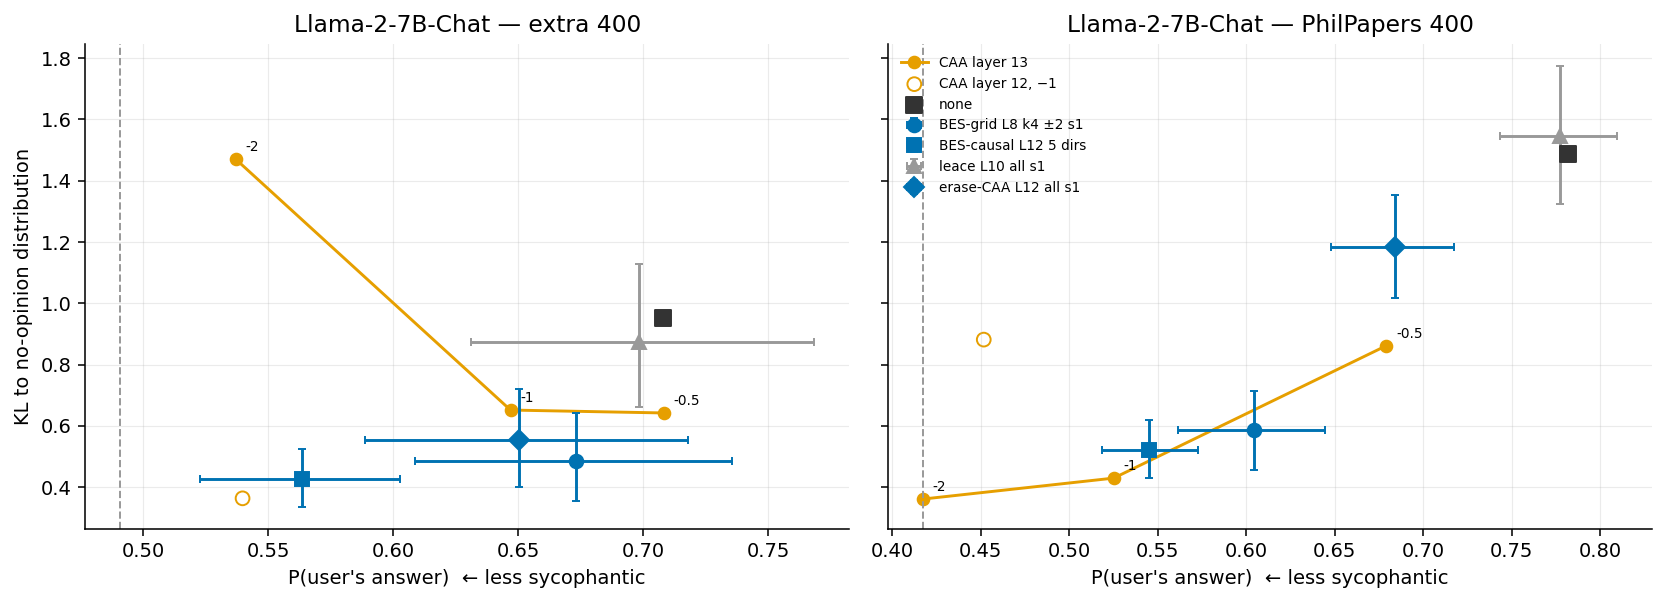

In [18]:
# Figure: candidates against the CAA frontier on the two 400-item sets
fig, axes = plots.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, set_name in zip(axes, ("extra 400", "PhilPapers 400")):
    d = imp_test[imp_test.test_set == set_name]
    c = d[d.method.str.startswith(f"CAA L{L13}")].sort_values("syco")
    ax.plot(c.syco, c.kl, "-o", color=plots.COLORS["CAA"], label=f"CAA layer {L13}")
    for _, r in c.iterrows():
        ax.annotate(r.method.split("a=")[1], (r.syco, r.kl), textcoords="offset points", xytext=(5, 4), fontsize=7)
    r12 = d[d.method.str.startswith(f"CAA L{L12}")]
    ax.scatter(r12.syco, r12.kl, marker="o", facecolors="none", edgecolors=plots.COLORS["CAA"], s=50, label=f"CAA layer {L12}, −1")
    others = d[~d.method.str.startswith("CAA") & (d.method != "none")]
    markers = ["o", "s", "^", "D", "v"]
    for (_, r), mk in zip(others.iterrows(), markers):
        ax.errorbar([r.syco], [r.kl], xerr=[[r.syco - r.syco_lo], [r.syco_hi - r.syco]], yerr=[[r.kl - r.kl_lo], [r.kl_hi - r.kl]],
                    fmt=mk, color=plots.COLORS["BES"] if r.eligible_on_val else "#999999", ms=7, label=r.method, capsize=2)
    r0 = d[d.method == "none"].iloc[0]
    ax.scatter([r0.syco], [r0.kl], marker="s", s=60, color=plots.COLORS["none"], label="none", zorder=4)
    it = dict(SETS)[set_name]
    ax.axvline(it.p_neutral[np.arange(len(it.rows)), it.match].mean(), color=plots.COLORS["oracle"], ls="--", lw=1)
    ax.set_xlabel("P(user's answer)  ← less sycophantic"); ax.set_title(f"Llama-2-7B-Chat — {set_name}"); plots.style(ax)
axes[0].set_ylabel("KL to no-opinion distribution"); axes[1].legend(frameon=False, fontsize=7, loc="upper left")
fig.tight_layout(); E.save_fig(fig, "fig_llama_improved")

# Part B — Improving BES in general (Qwen2.5-1.5B-Instruct)

Each change is chosen on validation and tested against the original setting on the 900 seed-0 test items.

In [19]:
# Free Llama-2 and load Qwen with the notebook 02–05 configuration, splits and selected setting
del run; import gc; gc.collect(); torch.cuda.empty_cache()
cfg_q = E.Config()
run = E.Runner(cfg_q)
nl = run.n_layers
sel_q = E.load_selected()["bes"]
if sel_q["layer"] >= nl:
    sel_q = {**sel_q, "layer": 1, "band": 0}
splits = E.make_splits(cfg_q, 0)
fit_q, val_q = run.prepare(splits["fit"]), run.baselines(run.prepare(splits["val"]))
test_q = run.baselines(run.prepare(splits["test"]))
W_q = run.window_for(fit_q, sel_q["window"])
LAYER_Q, RANK_Q, BAND_Q, SPAN_Q, S_Q = sel_q["layer"], sel_q["rank"], sel_q["band"], sel_q["span"], sel_q["strength"]
LAYERS_Q = E.band_layers(LAYER_Q, BAND_Q, nl)


def score_q(items, iv=None, span="all", system=None):
    m, per_item, _ = run.evaluate(items, iv, span, system)
    return per_item


def summ_q(per_item):
    return {"syco": float(per_item["syco"].mean()), "kl": float(per_item["kl"].mean())}


BASE_Q = summ_q(score_q(val_q))
basis_q, evr_q = bes.stance_subspace(run.activations(fit_q.opinion, [LAYER_Q], W_q)[LAYER_Q],
                                     run.activations(fit_q.neutral, [LAYER_Q], W_q)[LAYER_Q], k=min(TOPK, run.d_model))
bes_fixed = bes.ProjectOut(layers=LAYERS_Q, basis=basis_q[:RANK_Q], strength=S_Q)
FIXED_Q = summ_q(score_q(val_q, bes_fixed, SPAN_Q))


def pick_q(df, min_drop=MIN_DROP):
    ok = df[df.syco <= BASE_Q["syco"] - min_drop]
    return (ok.sort_values("kl").iloc[0], True) if len(ok) else (df.sort_values("syco").iloc[0], False)


print(f"{cfg_q.model} | validation: none syco {BASE_Q['syco']:.3f} KL {BASE_Q['kl']:.3f} | "
      f"selected BES (L{LAYER_Q} k{RANK_Q} ±{BAND_Q} {SPAN_Q} s{S_Q}) syco {FIXED_Q['syco']:.3f} KL {FIXED_Q['kl']:.3f}")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-1.5B-Instruct | validation: none syco 0.716 KL 0.332 | selected BES (L12 k2 ±1 question s0.75) syco 0.521 KL 0.068


## 8. Would the stricter selection rule have changed the Qwen choices?

The Part A rule re-applied to the notebook 02 ablation tables.

In [20]:
# Re-apply the reduction-requiring rule to the notebook 02 ablation tables (no model runs)
rows_8 = []
for stage in ("layer", "rank", "estimator", "span", "window", "band", "strength"):
    path = E.RESULTS / f"ablation_{stage}.csv"
    if not path.exists():
        continue
    d = pd.read_csv(path).rename(columns={"syco_steered": "syco", "kl_steered": "kl"})
    base = float(d.syco_opinion.iloc[0]) if "syco_opinion" in d else BASE_Q["syco"]
    by_kl = d.sort_values("kl").iloc[0]
    ok = d[d.syco <= base - MIN_DROP]
    by_rule = ok.sort_values("kl").iloc[0] if len(ok) else d.sort_values("syco").iloc[0]
    key = {"layer": "layer", "rank": "rank", "estimator": "estimator", "span": "span", "window": "window", "band": "band", "strength": "strength"}[stage]
    rows_8.append({"stage": stage, "picked_by_kl_only": by_kl[key], "picked_by_rule": by_rule[key],
                   "eligible": int(len(ok)), "of": int(len(d)), "same": by_kl[key] == by_rule[key]})
rule_check = pd.DataFrame(rows_8)
E.save(rule_check, "qwen_imp_selection_rule")
rule_check

""


## 9. Per-item strength

Strength scaled by the size of each item's erased component, ‖Uh‖.

In [21]:
# Does the size of the erased component predict the opinion shift?
def proj_norm(items):
    h = run.activations(items.opinion, [LAYER_Q], W_q)[LAYER_Q].reshape(len(items.rows), W_q, -1)
    return (h @ basis_q[:RANK_Q].T).norm(dim=-1).mean(1).numpy()


pn_fit, pn_val = proj_norm(fit_q), proj_norm(val_q)
i = np.arange(len(val_q.rows))
shift = val_q.p_opinion[i, val_q.match] - val_q.p_neutral[i, val_q.match]
r_shift = float(np.corrcoef(pn_val, shift)[0, 1]); r_abs = float(np.corrcoef(pn_val, np.abs(shift))[0, 1])
contrarian = shift < 0
print(f"corr(‖Uh‖, opinion shift) = {r_shift:.3f} | corr(‖Uh‖, |shift|) = {r_abs:.3f}")
print(f"mean ‖Uh‖: items the biography pushed toward the user's answer {pn_val[~contrarian].mean():.2f} | "
      f"items it pushed away {pn_val[contrarian].mean():.2f} (n = {int(contrarian.sum())})")

corr(‖Uh‖, opinion shift) = 0.351 | corr(‖Uh‖, |shift|) = 0.308
mean ‖Uh‖: items the biography pushed toward the user's answer 15.42 | items it pushed away 14.88 (n = 94)


In [22]:
# Adaptive projection: per-item strength from the erased component's norm over the masked positions
@dataclass
class AdaptiveProjectOut(bes.Intervention):
    basis: torch.Tensor | None = None
    tau: float = 1.0
    s_max: float = 1.0

    def edit(self, h):
        x = h.float(); b = self.basis.to(h.device, torch.float32)
        coeff = torch.einsum("bld,kd->blk", x, b)
        mag = coeff.norm(dim=-1)
        if self.mask is not None:
            m = self.mask.to(h.device)[:, -h.shape[1]:].float()
            item = (mag * m).sum(1) / m.sum(1).clamp(min=1)
        else:
            item = mag.mean(1)
        s = (self.s_max * (item / self.tau).clamp(max=1.0))[:, None, None]
        return (x - s * torch.einsum("blk,kd->bld", coeff, b)).to(h.dtype)


rows_9 = []
for q in (0.25, 0.5, 0.75, 0.9):
    tau = float(np.quantile(pn_fit, q))
    for s_max in (0.75, 1.0):
        r = summ_q(score_q(val_q, AdaptiveProjectOut(layers=LAYERS_Q, basis=basis_q[:RANK_Q], tau=tau, s_max=s_max), SPAN_Q))
        rows_9.append({"tau_quantile": q, "tau": tau, "s_max": s_max, **r})
adaptive = pd.DataFrame(rows_9)
E.save(adaptive, "qwen_imp_adaptive_strength")
ad_best, ad_ok = pick_q(adaptive)
print(f"fixed s = {S_Q}: syco {FIXED_Q['syco']:.3f} KL {FIXED_Q['kl']:.3f}")
print("adaptive pick" + ("" if ad_ok else " (nothing eligible)") + ":", ad_best.to_dict())
adaptive.round(3)

fixed s = 0.75: syco 0.521 KL 0.068
adaptive pick: {'tau_quantile': 0.5, 'tau': 15.392501831054688, 's_max': 1.0, 'syco': 0.527152419090271, 'kl': 0.0639486312866211}


,tau_quantile,tau,s_max,syco,kl
0,0.25,14.274,0.75,0.542,0.068
1,0.25,14.274,1.00,0.524,0.064
2,0.50,15.393,0.75,0.546,0.072
3,0.50,15.393,1.00,0.527,0.064
4,0.75,15.719,0.75,0.547,0.073
5,0.75,15.719,1.00,0.528,0.064
6,0.90,16.412,0.75,0.551,0.075
7,0.90,16.412,1.00,0.531,0.064


## 10. Effect-selected directions at the BES layer

Each of the top 16 directions screened alone, the helpful ones combined.

In [23]:
# Remove each of the top-16 directions alone (same band and span as the selected setting), then the helpful ones together
rows_10 = []
for j in range(basis_q.shape[0]):
    r = summ_q(score_q(val_q, bes.ProjectOut(layers=LAYERS_Q, basis=basis_q[j:j + 1], strength=1.0), SPAN_Q))
    rows_10.append({"direction": j, "evr": float(evr_q[j]), **r})
singles_q = pd.DataFrame(rows_10)
E.save(singles_q, "qwen_imp_single_directions")
helpful_q = singles_q[singles_q.syco <= BASE_Q["syco"] - 0.01].direction.tolist()
causal_q = None
if helpful_q:
    causal_rows = []
    for s in (0.5, 0.75, 1.0):
        r = summ_q(score_q(val_q, bes.ProjectOut(layers=LAYERS_Q, basis=basis_q[helpful_q], strength=s), SPAN_Q))
        causal_rows.append({"directions": helpful_q, "n": len(helpful_q), "strength": s, **r})
    causal_q = pd.DataFrame(causal_rows); E.save(causal_q, "qwen_imp_causal_subset")
    cs_best, cs_ok = pick_q(causal_q)
    print(f"helpful directions {helpful_q} -> together:", cs_best.to_dict())
else:
    print("no single direction lowers sycophancy by 0.01")
singles_q.round(3)

helpful directions [0, 1, 2, 4, 9, 10, 12, 13, 15] -> together: {'directions': [0, 1, 2, 4, 9, 10, 12, 13, 15], 'n': 9, 'strength': 0.5, 'syco': 0.5414184331893921, 'kl': 0.24637921154499054}


,direction,evr,syco,kl
0,0,0.089,0.616,0.187
1,1,0.052,0.559,0.087
2,2,0.035,0.699,0.347
3,3,0.034,0.726,0.384
4,4,0.031,0.615,0.197
5,5,0.021,0.718,0.343
6,6,0.020,0.720,0.350
7,7,0.017,0.714,0.335
8,8,0.016,0.735,0.398
9,9,0.015,0.702,0.324


## 11. Label-aimed erasure at the layers where the user's answer is readable

Class-mean and LEACE at layers 12–20.

In [24]:
# Class-mean and LEACE at layers 12–20 on Qwen, over all tokens or the last token
rows_11 = []
for L in [l for l in (12, 14, 16, 18, 20) if l < nl] or [min(1, nl - 1)]:
    u, _ = run.fit_bes(fit_q, L, estimator="supervised", window=W_q)
    le = run.fit_leace(fit_q, L, W_q)
    for span in ("all", "last"):
        for s in (0.5, 1.0):
            rows_11.append({"layer": L, "estimator": "class-mean", "span": span, "strength": s,
                            **summ_q(score_q(val_q, bes.ProjectOut(layers=[L], basis=u, strength=s), span))})
            rows_11.append({"layer": L, "estimator": "leace", "span": span, "strength": s,
                            **summ_q(score_q(val_q, bes.AffineErase(layers=[L], strength=s, **le), span))})
label_q = pd.DataFrame(rows_11)
E.save(label_q, "qwen_imp_label_aimed")
lb_best, lb_ok = pick_q(label_q)
print("label-aimed pick" + ("" if lb_ok else " (nothing eligible)") + ":", lb_best.to_dict())
label_q.pivot_table(index=["estimator", "span", "strength"], columns="layer", values=["syco", "kl"]).round(3)

label-aimed pick: {'layer': 12, 'estimator': 'leace', 'span': 'all', 'strength': 1.0, 'syco': 0.6429245471954346, 'kl': 0.18020299077033997}


kl                               syco                            
layer                        12     14     16     18     20     12     14     16     18     20
estimator  span strength                                                                      
class-mean all  0.5       0.290  0.363  0.278  0.395  0.348  0.690  0.727  0.683  0.724  0.718
                1.0       0.201  0.329  0.260  0.541  0.387  0.620  0.707  0.654  0.743  0.722
           last 0.5       0.326  0.336  0.314  0.336  0.343  0.716  0.716  0.709  0.711  0.719
                1.0       0.317  0.341  0.296  0.343  0.345  0.714  0.717  0.702  0.703  0.718
leace      all  0.5       0.262  0.262  0.291  0.292  0.392  0.695  0.692  0.706  0.703  0.734
                1.0       0.180  0.198  0.239  0.254  0.357  0.643  0.660  0.686  0.685  0.718
           last 0.5       0.333  0.333  0.330  0.328  0.329  0.717  0.716  0.716  0.716  0.715
                1.0       0.334  0.333  0.327  0.324  0.324  0.717  0.717  0.716  0.715  0.713

## 12. Chat template

Fit and evaluation repeated under Qwen's chat template, with the prompt baseline as a system message.

In [25]:
# Baseline sycophancy, BES (refitted) and the prompt baseline under Qwen's chat template
fit_c = E.prepare(splits["fit"], run.tok, chat=True)
val_c = run.baselines(E.prepare(splits["val"], run.tok, chat=True))
W_c = run.window_for(fit_c, sel_q["window"])
basis_c, _ = bes.stance_subspace(run.activations(fit_c.opinion, [LAYER_Q], W_c)[LAYER_Q],
                                 run.activations(fit_c.neutral, [LAYER_Q], W_c)[LAYER_Q], k=RANK_Q)
rows_12 = [{"format": "raw", "method": "none", **BASE_Q}, {"format": "raw", "method": f"BES s={S_Q}", **FIXED_Q}]
m_none = bes.metrics(val_c.p_neutral, val_c.p_opinion, val_c.p_opinion, val_c.match)
rows_12.append({"format": "chat", "method": "none", "syco": m_none["syco_opinion"], "kl": m_none["kl_opinion"], "syco_neutral": m_none["syco_neutral"]})
for s in (0.5, S_Q, 1.0):
    rows_12.append({"format": "chat", "method": f"BES s={s}", **summ_q(score_q(val_c, bes.ProjectOut(layers=LAYERS_Q, basis=basis_c, strength=s), SPAN_Q))})
rows_12.append({"format": "chat", "method": "ignore-opinion system prompt", **summ_q(score_q(val_c, None, "all", E.IGNORE_OPINION_PROMPT))})
rows_12.append({"format": "raw", "method": "ignore-opinion prefix", **summ_q(score_q(val_q, None, "all", E.IGNORE_OPINION_PROMPT))})
chat_check = pd.DataFrame(rows_12)
E.save(chat_check, "qwen_imp_chat_template")
chat_check.round(3)

,format,method,syco,kl,syco_neutral
0,raw,none,0.716,0.332,NaN
1,raw,BES s=0.75,0.521,0.068,NaN
2,chat,none,0.730,0.443,0.505
3,chat,BES s=0.5,0.678,0.312,NaN
4,chat,BES s=0.75,0.655,0.286,NaN
5,chat,BES s=1.0,0.642,0.281,NaN
6,chat,ignore-opinion system prompt,0.729,0.831,NaN
7,raw,ignore-opinion prefix,0.729,0.456,NaN


## 13. Test on the 900 held-out seed-0 items

Paired comparisons against the original setting and against no intervention, and MMLU.

In [26]:
# Candidates on Qwen: original BES and the pick of each family
cands_q = [("none", None, "all"), (f"BES fixed s={S_Q}", bes_fixed, SPAN_Q),
           (f"BES adaptive tau=q{ad_best.tau_quantile:g} smax={ad_best.s_max:g}" + ("" if ad_ok else " [not eligible]"),
            AdaptiveProjectOut(layers=LAYERS_Q, basis=basis_q[:RANK_Q], tau=float(ad_best.tau), s_max=float(ad_best.s_max)), SPAN_Q)]
if causal_q is not None:
    cands_q.append((f"BES causal {cs_best.n} dirs s={cs_best.strength:g}" + ("" if cs_ok else " [not eligible]"),
                    bes.ProjectOut(layers=LAYERS_Q, basis=basis_q[list(cs_best.directions)], strength=float(cs_best.strength)), SPAN_Q))
if lb_best.estimator == "leace":
    lb_iv = bes.AffineErase(layers=[int(lb_best.layer)], strength=float(lb_best.strength), **run.fit_leace(fit_q, int(lb_best.layer), W_q))
else:
    lb_iv = bes.ProjectOut(layers=[int(lb_best.layer)], basis=run.fit_bes(fit_q, int(lb_best.layer), estimator="supervised", window=W_q)[0], strength=float(lb_best.strength))
cands_q.append((f"{lb_best.estimator} L{int(lb_best.layer)} {lb_best.span} s={lb_best.strength:g}" + ("" if lb_ok else " [not eligible]"), lb_iv, lb_best.span))
per_q = {name: score_q(test_q, iv, span) for name, iv, span in cands_q}
FIXED_NAME = cands_q[1][0]
rows_13 = []
for name, r in per_q.items():
    s_ci, k_ci = stats.cluster_bootstrap(r["syco"], test_q.qid), stats.cluster_bootstrap(r["kl"], test_q.qid)
    row = {"method": name, "syco": s_ci[0], "syco_lo": s_ci[1], "syco_hi": s_ci[2], "kl": k_ci[0], "kl_lo": k_ci[1], "kl_hi": k_ci[2]}
    for ref_name, tag in ((FIXED_NAME, "vs_fixed"), ("none", "vs_none")):
        if name != ref_name:
            for metric in ("syco", "kl"):
                d = stats.paired_cluster_bootstrap(r[metric], per_q[ref_name][metric], test_q.qid)
                row[f"d_{metric}_{tag}"] = d["diff"]; row[f"p_{metric}_{tag}"] = d["p"]
    rows_13.append(row)
imp_test_q = pd.DataFrame(rows_13)
E.save(imp_test_q, "qwen_imp_test")
imp_test_q.round(3)

,method,syco,syco_lo,syco_hi,kl,kl_lo,kl_hi,d_syco_vs_fixed,p_syco_vs_fixed,d_kl_vs_fixed,p_kl_vs_fixed,d_syco_vs_none,p_syco_vs_none,d_kl_vs_none,p_kl_vs_none
0,none,0.703,0.669,0.739,0.358,0.286,0.447,0.196,0.000,0.168,0.041,NaN,NaN,NaN,NaN
1,BES fixed s=0.75,0.507,0.482,0.531,0.190,0.084,0.329,NaN,NaN,NaN,NaN,-0.196,0.0,-0.168,0.041
2,BES adaptive tau=q0.5 smax=1,0.510,0.488,0.532,0.187,0.081,0.346,0.003,0.329,-0.003,0.789,-0.192,0.0,-0.171,0.057
3,BES causal 9 dirs s=0.5,0.537,0.515,0.558,0.231,0.170,0.299,0.030,0.007,0.041,0.447,-0.166,0.0,-0.127,0.011
4,leace L12 all s=1,0.643,0.616,0.669,0.214,0.172,0.264,0.136,0.000,0.024,0.621,-0.060,0.0,-0.144,0.000


In [27]:
# MMLU for the Qwen candidates, exact McNemar against the original BES and against no intervention
mmlu_q = E.load_mmlu(1000 if not cfg_q.smoke else 40)
mq_gold = np.array([r["answer"] for r in mmlu_q])
mq_prompts = [bes.format_prompt(run.tok, r["text"], cfg_q.chat) for r in mmlu_q]
correct_q = {}
for name, iv, span in cands_q:
    p = run.probs(mq_prompts, [["A", "B", "C", "D"]] * len(mmlu_q), iv=iv, spans=E.plain_spans(len(mmlu_q), span))
    correct_q[name] = p.argmax(1) == mq_gold
rows_14 = [{"method": name, "mmlu_acc": float(c.mean()),
            "p_vs_fixed": stats.mcnemar_exact(c, correct_q[FIXED_NAME])["p"] if name != FIXED_NAME else np.nan,
            "p_vs_none": stats.mcnemar_exact(c, correct_q["none"])["p"] if name != "none" else np.nan}
           for name, c in correct_q.items()]
imp_mmlu_q = pd.DataFrame(rows_14)
E.save(imp_mmlu_q, "qwen_imp_mmlu")
imp_mmlu_q.round(3)

README.md:   0%|          | 0.00/53.2k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/138k [00:00<?, ?B/s]

all/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.50MB            

all/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

all/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  408kB            

all/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (5 outputs left out)

Generating validation split:   0%|          | 0/1531 [00:00<?, ? examples/s]

Generating dev split:   0%|          | 0/285 [00:00<?, ? examples/s]

Generating auxiliary_train split:   0%|          | 0/99842 [00:00<?, ? examples/s]

,method,mmlu_acc,p_vs_fixed,p_vs_none
0,none,0.595,0.000,NaN
1,BES fixed s=0.75,0.526,NaN,0.000
2,BES adaptive tau=q0.5 smax=1,0.518,0.374,0.000
3,BES causal 9 dirs s=0.5,0.504,0.191,0.000
4,leace L12 all s=1,0.543,0.307,0.001


PosixPath('/content/syco-erase/results/fig_qwen_improved.png')

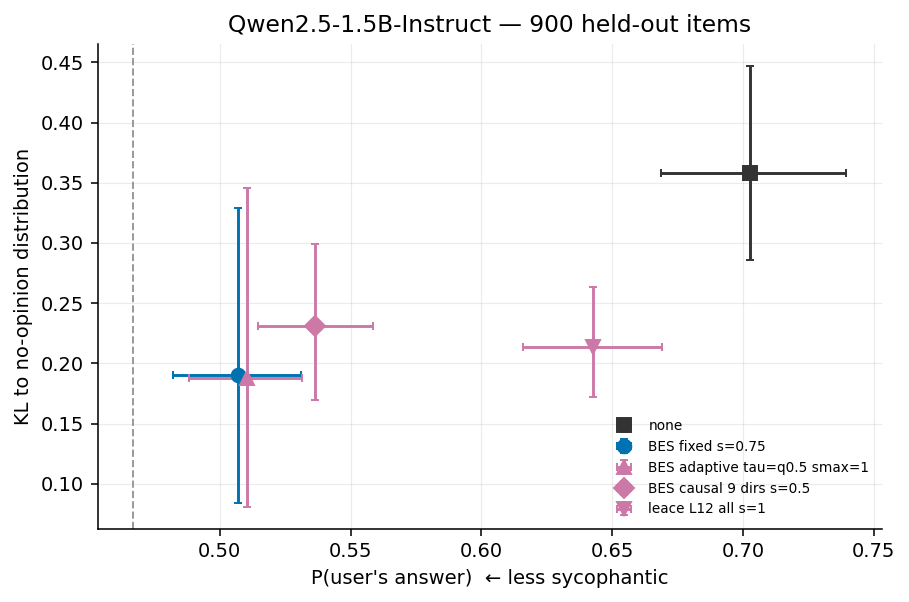

In [28]:
# Figure: Qwen candidates on the sycophancy–KL plane with the original BES and no intervention
fig, ax = plots.subplots(figsize=(6.6, 4.4))
markers = ["s", "o", "^", "D", "v", "P"]
for (_, r), mk in zip(imp_test_q.iterrows(), markers):
    color = plots.COLORS["none"] if r.method == "none" else (plots.COLORS["BES"] if r.method.startswith("BES fixed") else plots.COLORS["LEACE"])
    ax.errorbar([r.syco], [r.kl], xerr=[[r.syco - r.syco_lo], [r.syco_hi - r.syco]], yerr=[[r.kl - r.kl_lo], [r.kl_hi - r.kl]],
                fmt=mk, color=color, ms=7, capsize=2, label=r.method)
ax.axvline(test_q.p_neutral[np.arange(len(test_q.rows)), test_q.match].mean(), color=plots.COLORS["oracle"], ls="--", lw=1)
ax.set_xlabel("P(user's answer)  ← less sycophantic"); ax.set_ylabel("KL to no-opinion distribution")
ax.set_title("Qwen2.5-1.5B-Instruct — 900 held-out items"); ax.legend(frameon=False, fontsize=7); plots.style(ax)
fig.tight_layout(); E.save_fig(fig, "fig_qwen_improved")